# 2. Model comparison: getting past 90%

The project's target is 90% accuracy on the published TEST images. This notebook compares five pretrained mobile backbones, tunes the classifier head, and looks at what the best model still gets wrong.

**Method.** Every backbone is frozen and used as a feature extractor, so its output for each image is fixed. `eda/extract_features.py` computes those outputs once and caches them in `outputs/features/`. Training a classifier head on cached features takes about two seconds on a laptop, so all the comparisons below run without a GPU.

**Rule used throughout:** settings are chosen on the validation split (10% of the cleaned training data). TEST is only used to report the result.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "eda"))

import plotstyle as ps
from waste_classifier.data import CLASS_NAMES, resolve_data_dir
from waste_classifier.features import available_backbones, load_feature_set
from waste_classifier.head import train_head
from waste_classifier.model import BACKBONES

ps.apply()
DATA_DIR = resolve_data_dir(os.environ.get("WASTE_DATA_DIR", "~/Downloads/archive/DATASET"))
FEATURES_DIR = ROOT / "outputs" / "features"
TARGET = 0.90
backbones = available_backbones(FEATURES_DIR)
print("Cached features for:", backbones)

Cached features for: ['efficientnetb0', 'efficientnetv2b0', 'mobilenetv2', 'mobilenetv3large', 'mobilenetv3small']


## Baseline: no deep learning

How far do five colour statistics per image get (brightness, white-background share, mean red/green/blue)? This is the scikit-learn baseline: anything a neural network adds has to beat it. It reuses the per-image table from notebook 1.

In [2]:
stats = pd.read_csv(ROOT / "outputs" / "eda_image_stats.csv").set_index("path")
reference = load_feature_set(backbones[0], DATA_DIR, FEATURES_DIR)
rows = __import__("json").loads((FEATURES_DIR / "splits_seed42_val0.1.json").read_text())
index = __import__("json").loads((FEATURES_DIR / "index.json").read_text())
columns = ["brightness", "white_share", "red", "green", "blue"]

def colour_table(split):
    paths = [index[i]["path"] for i in sorted(rows[split])]
    return stats.loc[paths, columns].to_numpy()

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, class_weight="balanced"))
baseline.fit(colour_table("train"), reference.y_train)
baseline_val = baseline.score(colour_table("val"), reference.y_val)
baseline_test = baseline.score(colour_table("test"), reference.y_test)
print(f"Colour-statistics baseline: validation {baseline_val:.3f}, test {baseline_test:.3f}")

Colour-statistics baseline: validation 0.772, test 0.852


## Five backbones, same head, same settings

Each backbone gets the same head (standardise, dropout 0.2, one softmax layer, L2 0.003) trained three times with different random seeds. The table reports the mean; the spread across seeds shows how much of a difference is noise.

In [3]:
def score(head, fs):
    predicted = head.predict(fs.x_test, verbose=0).argmax(axis=1)
    return {
        "test_accuracy": (predicted == fs.y_test).mean(),
        "organic_recall": (predicted[fs.y_test == 0] == 0).mean(),
        "recyclable_recall": (predicted[fs.y_test == 1] == 1).mean(),
    }

feature_sets, runs = {}, []
for name in backbones:
    fs = feature_sets[name] = load_feature_set(name, DATA_DIR, FEATURES_DIR)
    for seed in (1, 2, 3):
        start = time.time()
        head, history = train_head(fs, seed=seed)
        runs.append({"backbone": name, "seed": seed, "features": fs.x_train.shape[1],
                     "val_accuracy": max(history["val_accuracy"]), **score(head, fs),
                     "seconds": time.time() - start})
runs = pd.DataFrame(runs)
comparison = (runs.groupby("backbone")
              .agg(features=("features", "first"), val_accuracy=("val_accuracy", "mean"),
                   test_accuracy=("test_accuracy", "mean"), test_min=("test_accuracy", "min"),
                   test_max=("test_accuracy", "max"), organic_recall=("organic_recall", "mean"),
                   recyclable_recall=("recyclable_recall", "mean"), seconds=("seconds", "mean"))
              .sort_values("test_accuracy", ascending=False))
comparison.round(4)

,features,val_accuracy,test_accuracy,test_min,test_max,organic_recall,recyclable_recall,seconds
backbone,,,,,,,,
mobilenetv3small,576,0.9409,0.9386,0.9363,0.9423,0.9807,0.8855,2.6743
mobilenetv3large,960,0.9534,0.9351,0.9331,0.9391,0.9838,0.8738,4.5950
efficientnetv2b0,1280,0.9618,0.9248,0.9129,0.9316,0.9817,0.8531,3.6912
mobilenetv2,1280,0.9453,0.9105,0.9053,0.9140,0.9779,0.8255,3.4985
efficientnetb0,1280,0.9559,0.8989,0.8945,0.9049,0.9814,0.7950,6.8065


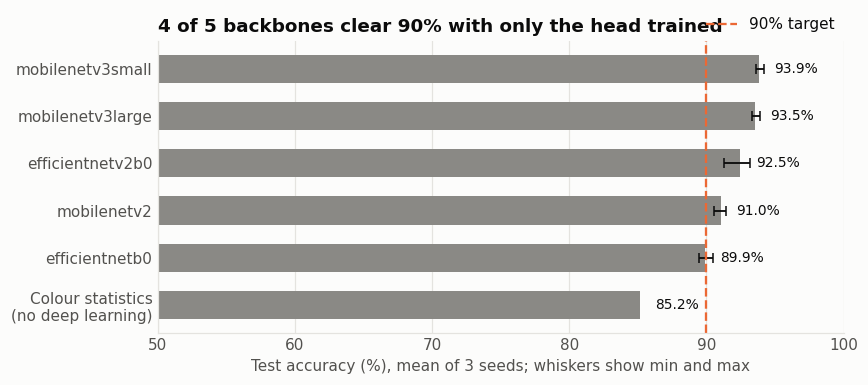

In [4]:
order = comparison.sort_values("test_accuracy").index.tolist()
labels = ["Colour statistics\n(no deep learning)"] + order
values = [baseline_test] + comparison.loc[order, "test_accuracy"].tolist()

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(labels, [v * 100 for v in values], color=ps.TRAIN, height=0.6)
low = [(comparison.loc[n, "test_accuracy"] - comparison.loc[n, "test_min"]) * 100 for n in order]
high = [(comparison.loc[n, "test_max"] - comparison.loc[n, "test_accuracy"]) * 100 for n in order]
ax.errorbar([v * 100 for v in values[1:]], range(1, len(labels)), xerr=[low, high],
            fmt="none", ecolor=ps.INK, elinewidth=1.2, capsize=3)
for y, v in enumerate(values):
    ax.annotate(f"{v:.1%}", (v * 100, y), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9)
ax.axvline(TARGET * 100, color=ps.TEST, lw=1.5, ls="--", label="90% target")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), borderaxespad=0.2)
ax.set_xlim(50, 100); ax.set_xlabel("Test accuracy (%), mean of 3 seeds; whiskers show min and max")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
cleared = int((comparison.test_accuracy >= TARGET).sum())
ax.set_title(f"{cleared} of {len(comparison)} backbones clear 90% with only the head trained")
fig.tight_layout()
ps.save(fig, "07_backbone_comparison.png")

## Where the errors are: recall by class

Accuracy hides which class is being missed. For every backbone, almost all Organic test images are caught, and the misses are Recyclable items labelled Organic.

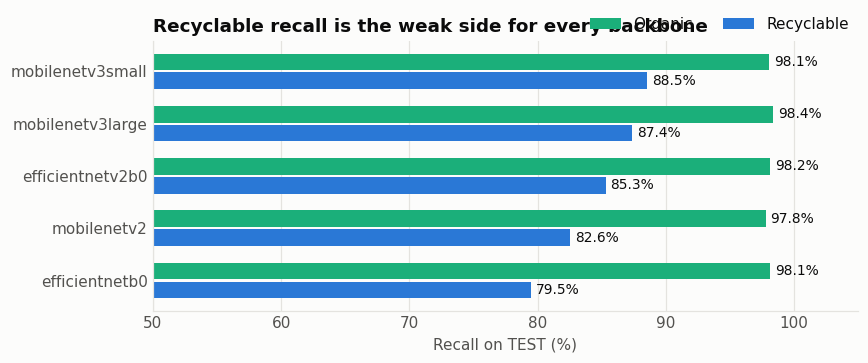

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(order)); h = 0.36
for offset, column, name in [(h / 2, "organic_recall", "Organic"), (-h / 2, "recyclable_recall", "Recyclable")]:
    bars = ax.barh(y + offset, comparison.loc[order, column] * 100, height=h - 0.04,
                   color=ps.CLASS_COLORS[name], label=name)
    ps.label_bars(ax, bars, fmt="{:.1f}%", horizontal=True)
ax.set_yticks(y, order); ax.set_xlim(50, 105); ax.set_xlabel("Recall on TEST (%)")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", ncols=2, bbox_to_anchor=(1, 1.0), borderaxespad=0.2)
ax.set_title("Recyclable recall is the weak side for every backbone")
fig.tight_layout()
ps.save(fig, "08_recall_by_class.png")

## Tuning the head

Two settings control how hard the head is regularised: dropout and L2 weight decay. The grid below is for the backbone with the best validation accuracy. Each cell is validation accuracy, since that is what settings are chosen on.

Spread across the grid: 0.9 points of validation accuracy
Best by validation: L2 0.0003, dropout 0.2 -> test accuracy 0.9276


,l2,dropout,val_accuracy,test_accuracy,organic_recall,recyclable_recall
0,0.0003,0.0,0.9604,0.9140,0.9736,0.8390
1,0.0003,0.2,0.9631,0.9276,0.9786,0.8633
2,0.0003,0.5,0.9586,0.9240,0.9786,0.8552
3,0.0030,0.0,0.9618,0.9196,0.9757,0.8489
4,0.0030,0.2,0.9618,0.9300,0.9800,0.8669
5,0.0030,0.5,0.9573,0.9252,0.9779,0.8588
6,0.0300,0.0,0.9568,0.9304,0.9786,0.8696
7,0.0300,0.2,0.9577,0.9268,0.9793,0.8606
8,0.0300,0.5,0.9541,0.9339,0.9764,0.8804


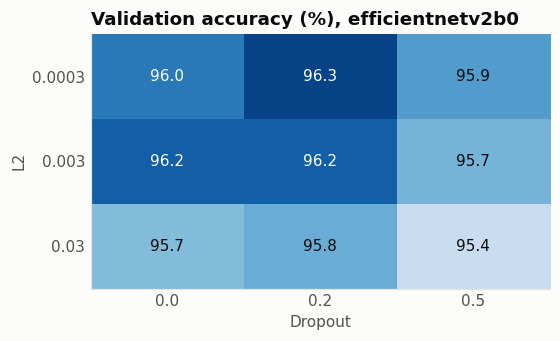

In [6]:
chosen = comparison["val_accuracy"].idxmax()
fs = feature_sets[chosen]
l2_values, dropout_values = [0.0003, 0.003, 0.03], [0.0, 0.2, 0.5]
grid = []
for l2 in l2_values:
    for dropout in dropout_values:
        head, history = train_head(fs, l2=l2, dropout=dropout, seed=1)
        grid.append({"l2": l2, "dropout": dropout, "val_accuracy": max(history["val_accuracy"]),
                     **score(head, fs)})
grid = pd.DataFrame(grid)
val_grid = grid.pivot(index="l2", columns="dropout", values="val_accuracy")

fig, ax = plt.subplots(figsize=(5.2, 3.2))
image = ax.imshow(val_grid.values * 100, cmap="Blues", aspect="auto",
                  vmin=val_grid.values.min() * 100 - 0.3, vmax=val_grid.values.max() * 100 + 0.1)
ax.set_xticks(range(len(dropout_values)), dropout_values); ax.set_yticks(range(len(l2_values)), l2_values)
ax.set_xlabel("Dropout"); ax.set_ylabel("L2"); ax.grid(False)
for i in range(len(l2_values)):
    for j in range(len(dropout_values)):
        v = val_grid.values[i, j] * 100
        ax.text(j, i, f"{v:.1f}", ha="center", va="center",
                color="white" if v > val_grid.values.mean() * 100 else ps.INK)
ax.set_title(f"Validation accuracy (%), {chosen}")
fig.tight_layout()
ps.save(fig, "09_head_tuning.png")

best = grid.loc[grid.val_accuracy.idxmax()]
print(f"Spread across the grid: {(grid.val_accuracy.max() - grid.val_accuracy.min()) * 100:.1f} points of validation accuracy")
print(f"Best by validation: L2 {best.l2}, dropout {best.dropout} -> test accuracy {best.test_accuracy:.4f}")
grid.round(4)

## The selected model on TEST

Trained with the best settings from the grid, then scored once on TEST.

Test accuracy 0.9276 on 2,513 images (target 90%)


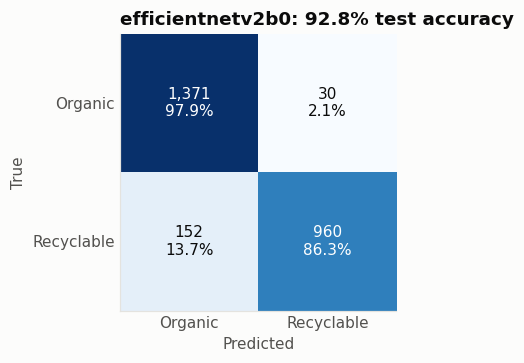

In [7]:
head, history = train_head(fs, l2=float(best.l2), dropout=float(best.dropout), seed=1)
probabilities = head.predict(fs.x_test, verbose=0)
predicted = probabilities.argmax(axis=1)
confidence = probabilities.max(axis=1)
correct = predicted == fs.y_test
matrix = pd.crosstab(pd.Series(fs.y_test, name="true"), pd.Series(predicted, name="predicted"))
matrix.index = matrix.columns = CLASS_NAMES

fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.imshow(matrix.values, cmap="Blues"); ax.grid(False)
ax.set_xticks(range(2), CLASS_NAMES); ax.set_yticks(range(2), CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(2):
    for j in range(2):
        share = matrix.values[i, j] / matrix.values[i].sum()
        ax.text(j, i, f"{matrix.values[i, j]:,}\n{share:.1%}", ha="center", va="center",
                color="white" if matrix.values[i, j] > matrix.values.max() / 2 else ps.INK)
ax.set_title(f"{chosen}: {correct.mean():.1%} test accuracy")
fig.tight_layout()
ps.save(fig, "10_confusion_matrix.png")
print(f"Test accuracy {correct.mean():.4f} on {len(correct):,} images (target {TARGET:.0%})")

## The 90% confidence gate

The app plan only awards points automatically when the model is at least 90% confident, and asks for a retake otherwise. This shows what that gate does on TEST: how many photos pass it, and how accurate the model is on those.

Wrong answers that still pass the gate: 34 of 182 errors


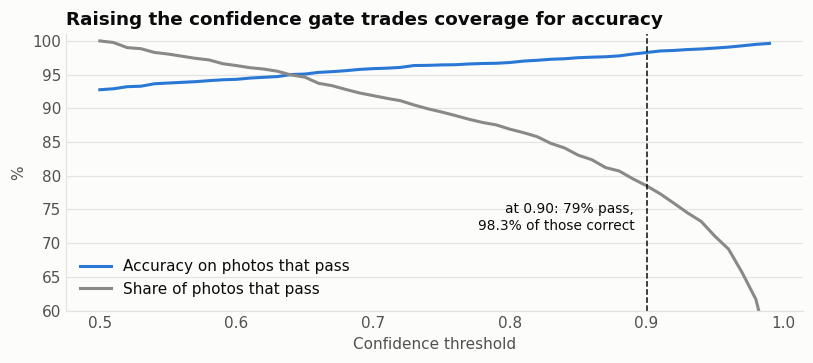

In [8]:
thresholds = np.linspace(0.5, 0.99, 50)
coverage = [(confidence >= t).mean() for t in thresholds]
accuracy = [correct[confidence >= t].mean() for t in thresholds]
gate = 0.90
passed = confidence >= gate

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(thresholds, np.array(accuracy) * 100, color=ps.RECYCLABLE, label="Accuracy on photos that pass")
ax.plot(thresholds, np.array(coverage) * 100, color=ps.TRAIN, label="Share of photos that pass")
ax.axvline(gate, color=ps.INK, lw=1, ls="--")
ax.annotate(f"at 0.90: {passed.mean():.0%} pass,\n{correct[passed].mean():.1%} of those correct",
            (gate, 72), xytext=(-8, 0), textcoords="offset points", ha="right", fontsize=9)
ax.set_xlabel("Confidence threshold"); ax.set_ylabel("%"); ax.set_ylim(60, 101)
ax.legend(loc="lower left")
ax.set_title("Raising the confidence gate trades coverage for accuracy")
fig.tight_layout()
ps.save(fig, "11_confidence_gate.png")
print(f"Wrong answers that still pass the gate: {(~correct & passed).sum()} of {(~correct).sum()} errors")

## What it gets wrong

The most confident mistakes on TEST. These are the cases the confidence gate will not catch.

Errors by true class: {'Recyclable': 152, 'Organic': 30}


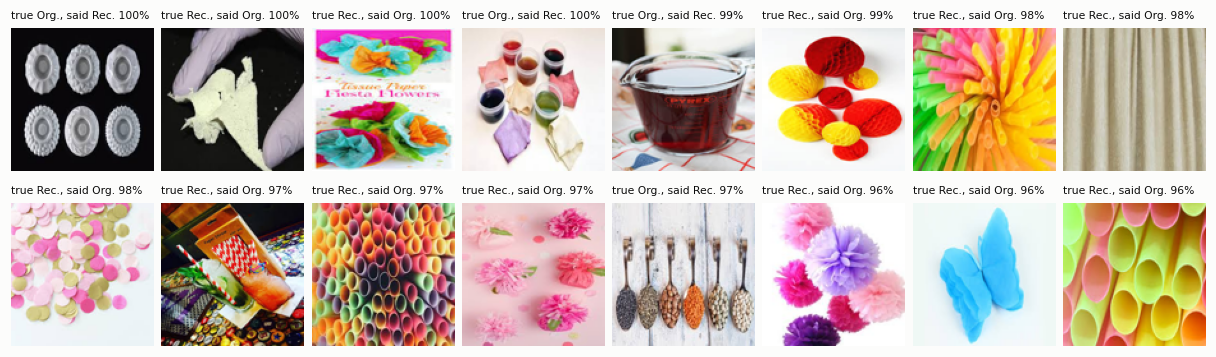

In [9]:
wrong = np.where(~correct)[0]
worst = wrong[np.argsort(-confidence[wrong])][:16]
fig, axes = plt.subplots(2, 8, figsize=(11, 3.4))
for ax, i in zip(axes.ravel(), worst):
    with Image.open(DATA_DIR / fs.test_paths[i]) as im:
        ax.imshow(im.convert("RGB").resize((112, 112)))
    ax.set_title(f"true {CLASS_NAMES[fs.y_test[i]][:3]}., said {CLASS_NAMES[predicted[i]][:3]}. {confidence[i]:.0%}",
                 fontsize=7, fontweight="normal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
fig.tight_layout(pad=0.5)
ps.save(fig, "12_confident_mistakes.png")
errors = pd.Series([CLASS_NAMES[t] for t in fs.y_test[wrong]]).value_counts()
print("Errors by true class:", errors.to_dict())

## Takeaways

- A frozen pretrained backbone with a trained head reaches the 90% target; no fine-tuning or GPU is needed for that.
- Validation and TEST rank the backbones differently, and validation accuracy is higher than TEST accuracy for every backbone. Notebook 1 shows TEST is not distributed like TRAIN, so treat differences of a point or two between backbones as unresolved.
- The remaining errors are mostly Recyclable items called Organic. Real phone photos are a further shift from both splits, so the team's own test photos matter more than another point here.